In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import matplotlib
from cycler import cycler

color = ['0.0', '0.4', '0.8']
plt.rc('axes', prop_cycle=cycler(color=color))
matplotlib.rcParams.update({'font.size': 18})

In [2]:
from pywrangling.jupyter_slides_functions import apply_beamer_theme
from pywrangling.graphing_functions import use_plotplainblind, set_top_ylabel
import statsmodels.formula.api as smf
import course_helpers as chh
apply_beamer_theme(
    "madrid",
    skip_font_download=True,
    author="Robert Pettis",
    date="Fall 2026",
    show_slide_number=True,
    cell_tags=True,
    notebook_path="15-Propensity-Score.ipynb",
)

<IPython.core.display.Javascript object>


✓ Cell tag CSS applied for 54 cell(s):
 cell_index    slide_id                                  tags
          1             slide_hide_prompt, slide_remove_input
          8   slide-1-1                     slide_hide_prompt
         10   slide-1-3                     slide_hide_prompt
         12   slide-1-5                     slide_hide_prompt
         16   slide-3-0 slide_hide_prompt, slide_remove_input
         19   slide-3-2                     slide_hide_prompt
         21   slide-3-4 slide_hide_prompt, slide_remove_input
         23   slide-3-6                     slide_hide_prompt
         25   slide-3-7 slide_hide_prompt, slide_remove_input
         27   slide-3-9 slide_hide_prompt, slide_remove_input
         29  slide-3-11                     slide_hide_prompt
         31  slide-3-12 slide_hide_prompt, slide_remove_input
         41   slide-5-2                     slide_hide_prompt
         43   slide-5-4                     slide_hide_prompt
         44   slide-5-5       

In [3]:
# Presenter clicker remap. Guarded so a student's Restart & Run All
# never breaks on it if pywrangling is missing.
try:
    from pywrangling.jupyter_slides_functions import enable_reveal_key_remap
    enable_reveal_key_remap({
        38: "left",         # Up arrow   -> previous  (clicker left button)
        40: "right",        # Down arrow -> next      (clicker right button)
        27: "up",           # Escape     -> up        (clicker play button)
        66: "down",         # B          -> down      (clicker stop button)
        116: None,          # F5         -> block refresh
        9:  "togglePause",  # Tab        -> black screen
    })
except Exception:
    pass  # not presenting, or pywrangling not installed

# Propensity Scores

### The treatment model as an estimator in its own right

Causal Machine Learning

## Before We Start: Updating Your Repo

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 12px; border-radius:8px; font-weight:700; font-size:.9em;">Reminder</span> &nbsp;same git rhythm as the setup lecture.

| command | what it does |
|---|---|
| `git pull upstream main` | grab today's lecture before class |
| `git checkout -b ps1` | a branch for your own work |
| `git add .` then `git commit -m "..."` | snapshot your changes |
| `git push origin ps1` | send it to your fork, then open a pull request |
| `git status` | what changed, any time |

### Last Time: Recurrent Networks and LSTM

- A recurrent network feeds its own output back in, so it handles <b style="color:#73000A;">sequences of any length</b>
- Multiplying by the same weight over and over makes gradients <b style="color:#73000A;">vanish or explode</b>
- <b style="color:#73000A;">LSTM</b> adds a second, gentler path for memory to travel along
- That is the end of the prediction half of this course. From here every method is aimed at <b style="color:#73000A;">an effect</b>


### Where We Are Going

- The problem: treatment was not assigned at random, so treated and untreated units are not comparable
- The fix in one sentence: <b style="color:#73000A;">build a comparison group that looks like the treated group</b>
- Nine villages we can match by hand, then the <b style="color:#73000A;">propensity score</b> when hand matching runs out
- Then why matching is the weaker way to use that score, and <b style="color:#73000A;">weighting</b> is the better one
- Finally two methods that enforce balance instead of checking for it: <b style="color:#73000A;">CEM</b> and <b style="color:#73000A;">entropy balancing</b>

## Clinics and Infant Mortality

- An NGO built health clinics in several villages
- Outcome: `imrate`, infant deaths per thousand, a year after the clinics opened
- Pre-program covariates: `povrate`, the poverty rate, and `pcdocs`, doctors per capita
- Nine villages, four with a clinic. 

In [4]:
vill = chh.clinic_data()
vill

,village,T,imrate,povrate,pcdocs
0,1,1,10,0.5,0.01
1,2,1,15,0.6,0.02
2,3,1,22,0.7,0.01
3,4,1,19,0.6,0.02
4,5,0,25,0.6,0.01
5,6,0,19,0.5,0.02
6,7,0,4,0.1,0.04
7,8,0,8,0.3,0.05
8,9,0,6,0.2,0.04


### The Naive Comparison

- Average infant mortality in the clinic villages, minus the average in the rest
- Watch the sign

In [5]:
clinic = vill.query("T == 1")["imrate"]
none = vill.query("T == 0")["imrate"]

print(f"villages with a clinic   {clinic.mean():6.2f}")
print(f"villages without         {none.mean():6.2f}")
print(f"naive difference         {clinic.mean() - none.mean():+6.2f}")

villages with a clinic    16.50
villages without          12.40
naive difference          +4.10


### Matching by Hand: One Variable

- Take each village that got a clinic and find the untreated village that <b style="color:#73000A;">looks most like it</b>
- Start with poverty rate alone
- Then compare the treated outcomes to the outcomes of the villages we picked

In [6]:
untreated = vill.query("T == 0")

for _, v in vill.query("T == 1").iterrows():
    gap = (untreated["povrate"] - v["povrate"]).abs()
    closest = untreated.loc[gap == gap.min(), "village"].tolist()
    print(f"village {int(v['village'])}  povrate {v['povrate']:.1f}"
          f"  ->  closest untreated {closest}")

village 1  povrate 0.5  ->  closest untreated [6]
village 2  povrate 0.6  ->  closest untreated [5]
village 3  povrate 0.7  ->  closest untreated [5]
village 4  povrate 0.6  ->  closest untreated [5]


### Two Variables, and It Gets Hard

- Now use poverty <b style="color:#73000A;">and</b> doctors per capita
- Village 1 has `povrate` .5 and `pcdocs` .01. Village 6 matches on poverty, village 5 matches on doctors
- Which is the better match depends on which variable mattered more to whoever chose the villages
- We do not know that, and with seven variables we could not eyeball it anyway
- What to do??

## The Curse of Dimensionality

This is a basic application of the **curse of dimensionality**...
- The more we try to match on...the less likely it is to find a good match
  - Data becomes "sparse"

## The Propensity Score

- <b style="color:#73000A;">Propensity score:</b> $e(X) = P(T = 1 \mid X)$
    - So right now we will deal with binary T...
- Rosenbaum and Rubin (1983): adjusting for $e(X)$ is enough
- If treated and untreated share the same $e(X)$, their $X$ distributions match
- Confounders collapse into a <b style="color:#73000A;">single</b> number to balance on

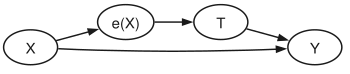

In [7]:
chh.draw_dag([("X", "e(X)"), ("e(X)", "T"), ("X", "Y"), ("T", "Y")])

### Rosenbaum and Rubin: Balancing Theorem

<b style="color:#73000A;">Theorem.</b> If $(Y_0, Y_1) \perp T \mid X$, then $(Y_0, Y_1) \perp T \mid e(X)$.

<b style="color:#73000A;">Proof sketch:</b>
$$P(Y_0, Y_1 \mid T, e(X)) = P(Y_0, Y_1 \mid e(X))$$
because
$$P(T = t \mid e(X), X) = P(T = t \mid e(X))$$
by definition of $e(X)$.

Controlling for the one-dimensional score is as good as controlling for $X$.

### Estimating the Score

- It is a prediction problem with the <b style="color:#73000A;">treatment</b> as the outcome: $P(T = 1 \mid X_1, \ldots, X_K)$
- Traditionally a logit or a probit. 
- Every village now carries one number summarising how likely it was to be chosen

In [8]:
ps_model = smf.logit("T ~ povrate + pcdocs", data=vill).fit(disp=0)
vill = vill.assign(ps=ps_model.predict(vill))

print(ps_model.params.round(2).to_string(), "\n")
vill.round(4)

Intercept    -7.50
povrate      14.50
pcdocs       -8.88 



,village,T,imrate,povrate,pcdocs,ps
0,1,1,10,0.5,0.01,0.4166
1,2,1,15,0.6,0.02,0.7358
2,3,1,22,0.7,0.01,0.9285
3,4,1,19,0.6,0.02,0.7358
4,5,0,25,0.6,0.01,0.7527
5,6,0,19,0.5,0.02,0.3952
6,7,0,4,0.1,0.04,0.0017
7,8,0,8,0.3,0.05,0.0268
8,9,0,6,0.2,0.04,0.0070


### Finding the Matches

- Use the score as the single variable to match on
- For each village with a clinic, take the untreated village with the <b style="color:#73000A;">closest score</b>

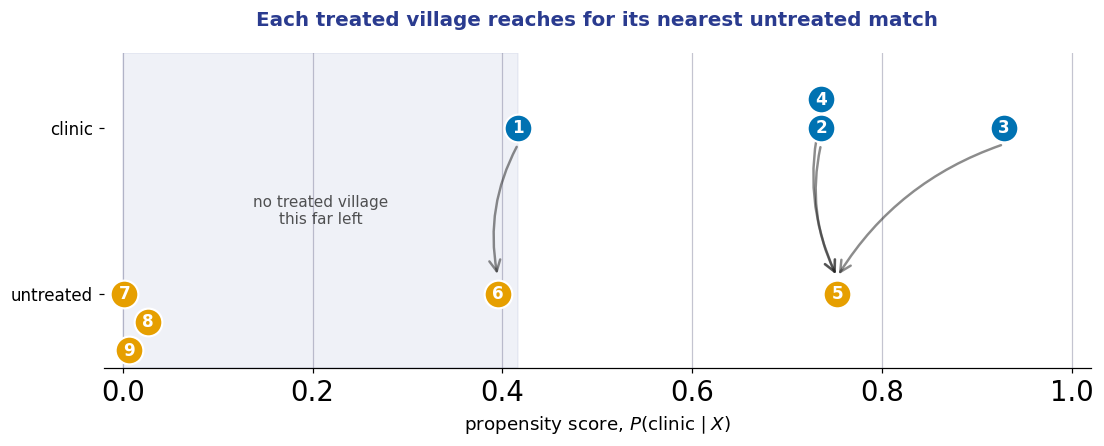

In [9]:
chh.fig_clinic_match()

### The Treatment Effect

$$\widehat{ATT} = \bar{Y}_{\text{treated}} - \bar{Y}_{\text{matched controls}}$$

- Average the four treated outcomes, average the four villages they matched to, subtract

In [10]:
match = chh.clinic_matches()           # each treated village's nearest by score
matched = [vill.loc[vill["village"] == m, "imrate"].item()
           for m in match.values()]

print("matches (treated -> control):", match)
print(f"treated mean           {clinic.mean():6.2f}")
print(f"matched control mean   {np.mean(matched):6.2f}")
print(f"ATT                    {clinic.mean() - np.mean(matched):+6.2f}")

matches (treated -> control): {1: 6, 2: 5, 3: 5, 4: 5}
treated mean            16.50
matched control mean    23.50
ATT                     -7.00


### More on the ATT

- We matched <b style="color:#73000A;">to</b> the treated villages, so we estimated the effect <b style="color:#73000A;">on</b> the treated
- It answers: how did the clinics work in the villages that got one?
- It does not answer: what would a clinic do in a village like number 7?


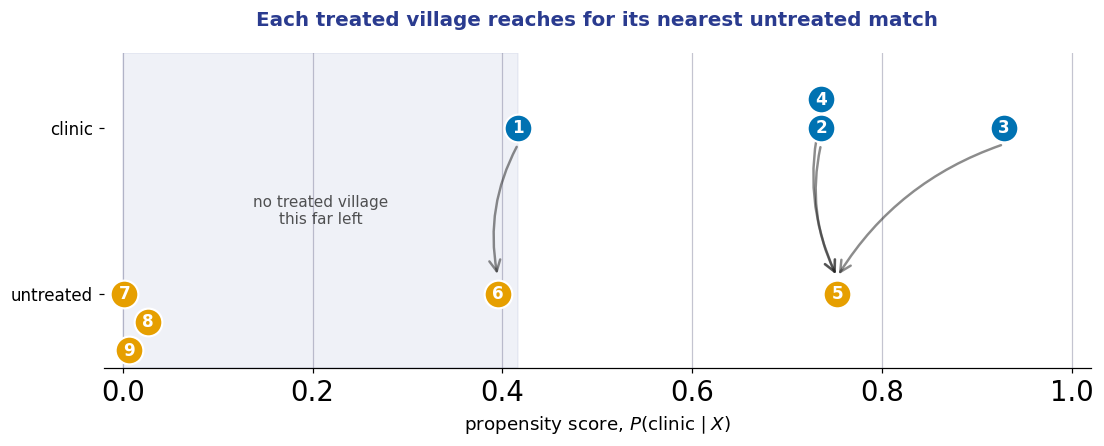

In [11]:
chh.fig_clinic_match()

### Matching the Other Way

- Matching can still take a guess at village 7. Run the same recipe in <b style="color:#73000A;">reverse</b>
- For each village <b style="color:#73000A;">without</b> a clinic, take the clinic village with the closest score
- Its outcome stands in for what the untreated village would have had with a clinic
- Matching to the untreated villages estimates the effect <b style="color:#73000A;">on the untreated</b>, the <b style="color:#73000A;">ATU</b>

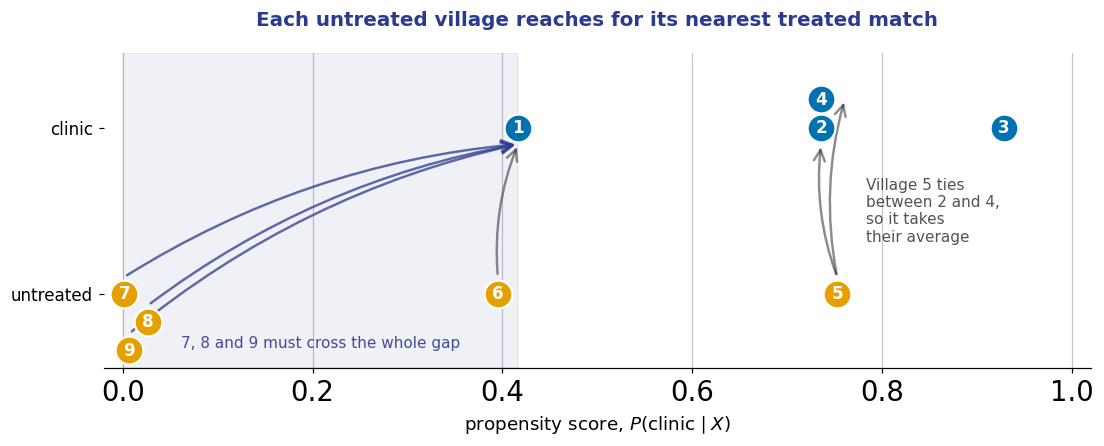

In [12]:
chh.fig_clinic_match_reverse()

### The Matching Estimator

$$\widehat{ATE} = \frac{1}{N}\sum_{i=1}^{N}\Big\{\big(Y_i - Y_{jm}(i)\big)T_i + \big(Y_{jm}(i) - Y_i\big)(1 - T_i)\Big\}$$

$$ \begin{cases} \underbrace{Y_i}_{\text{real outcome}} \;-\; \underbrace{Y_{jm}(i)}_{\text{match (untreated)}} & \text{if treated, } T_i = 1 \\[2.2em] \underbrace{Y_{jm}(i)}_{\text{match (treated)}} \;-\; \underbrace{Y_i}_{\text{real outcome (not treated)}} & \text{if not treated, } T_i = 0 \end{cases}$$

- $N = 9$ villages. $T_i$ is $1$ if village $i$ got a clinic and $0$ if not
- $Y_{jm}(i)$ is the outcome of village $i$'s match: the closest village <b style="color:#73000A;">in the other group</b>
- Either way the gap is treated minus untreated. Average it over the $N_1 = 4$ clinic villages only and you get the ATT; over the $N_0 = 5$ others, the ATU

In [13]:
rev = chh.clinic_matches_reverse()     # each untreated village's nearest by score
y = vill.set_index("village")["imrate"]

# Y_jm(i): the match's outcome. Village 5 ties between 2 and 4, so it averages them
y_jm = {v: y[m] for v, m in match.items()}
y_jm.update({v: y[ms].mean() for v, ms in rev.items()})

tab = vill[["village", "T", "imrate"]].assign(y_jm=vill["village"].map(y_jm))
T, Y, Yjm = tab["T"], tab["imrate"], tab["y_jm"]
tab["gap"] = (Y - Yjm) * T + (Yjm - Y) * (1 - T)
print(tab.to_string(index=False), "\n")

att = tab.query("T == 1")["gap"].mean()
atu = tab.query("T == 0")["gap"].mean()
ate = tab["gap"].mean()
print(f"ATT {att:+6.2f}   ATU {atu:+6.2f}   ATE {ate:+6.2f}")

 village  T  imrate  y_jm   gap
       1  1      10  19.0  -9.0
       2  1      15  25.0 -10.0
       3  1      22  25.0  -3.0
       4  1      19  25.0  -6.0
       5  0      25  17.0  -8.0
       6  0      19  10.0  -9.0
       7  0       4  10.0   6.0
       8  0       8  10.0   2.0
       9  0       6  10.0   4.0 

ATT  -7.00   ATU  -1.00   ATE  -3.67


### Review the ATU

- Villages 5 and 6 have treated neighbors close by. 
   - Their gaps are $-8$ and $-9$, right in line with the ATT
- Villages 7, 8 and 9 all borrow village 1, about $0.4$ away in score. 
   - Their gaps are $+6$, $+2$ and $+4$
- That says clinics <b style="color:#73000A;">raise</b> infant mortality. 
   - It is really village 1, poverty rate $.5$, standing in for villages at $.1$ to $.3$


With no clinic villages near 7, 8 and 9, a good ATE here is <b style="color:#73000A;">not available</b>

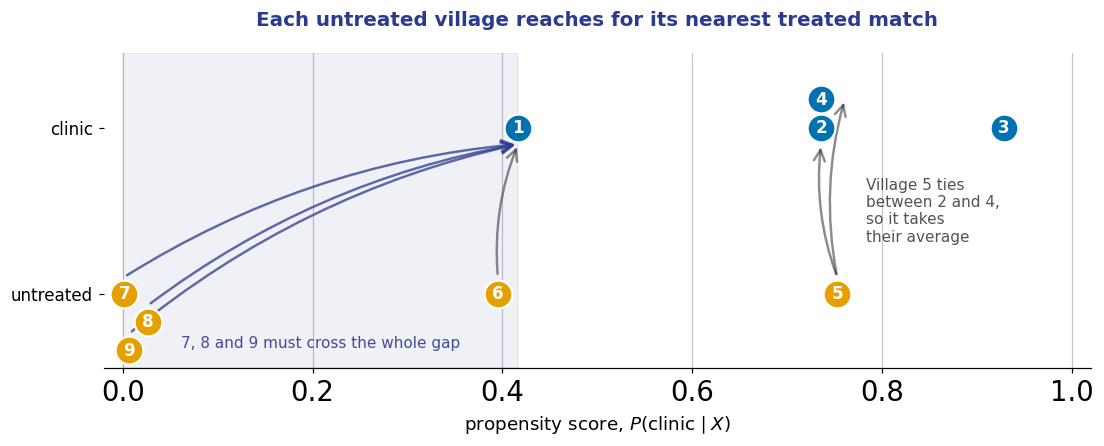

In [14]:
chh.fig_clinic_match_reverse()

### Can We Trust These Comparisons?

- **Balance:** Are the treated villages and matched controls similar in poverty and doctors per capita?
- **Overlap:** Are treated and untreated villages found at similar propensity scores?
- **Common support:** Where do the two groups’ score ranges intersect?

Matching needs comparable villages. Choosing the nearest village does not guarantee a good match.

### Balance: Did Matching Make the Groups More Similar?

Compare the average poverty rate and doctors per capita for:
- Treated villages
- All untreated villages
- Matched untreated villages

**Did matching bring the control averages closer to the treated averages?**

Check each variable separately...they use different units.
   - Could use **standardized mean difference (SMD)**...

### Did Matching Improve Balance?

- **Poverty rate:** The selected matches average **0.575**, much closer to the clinic villages’ **0.600** than the full untreated group’s **0.340**.
- **Doctors per capita:** The selected matches average **0.012**, closer to the clinic villages’ **0.015** than the full untreated group’s **0.032**.

**Matching brought both averages closer to those of the clinic villages.**

In [15]:
tr = vill.query("T == 1")
raw = vill.query("T == 0")
mch = vill.set_index("village").loc[list(match.values())]

cov = ["povrate", "pcdocs"]

balance = pd.DataFrame({
    "Clinic villages": tr[cov].mean(),
    "All non-clinic villages": raw[cov].mean(),
    "Selected matches": mch[cov].mean()
})

display(balance.round(3))

,Clinic villages,All non-clinic villages,Selected matches
povrate,0.600,0.340,0.575
pcdocs,0.015,0.032,0.012


### Overlap and Support: Are Comparisons Available?

Which villages fall outside the other group’s score range?

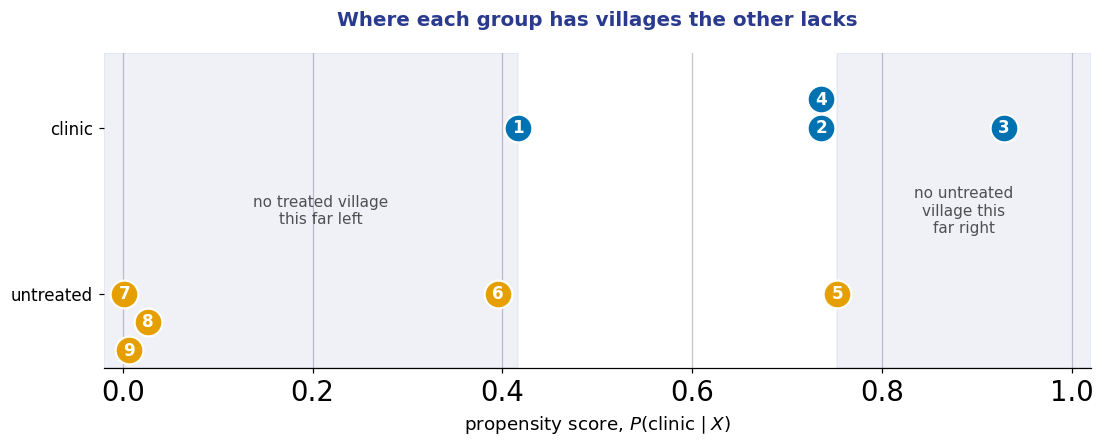

Clinic villages outside the non-clinic score range: [3]

Clinic village scores range from 0.417 to 0.928
Non-clinic villages below that range: [6, 7, 8, 9]

Selected matches:
  Village 5: selected 3 time(s)
  Village 6: selected 1 time(s)

4 matches use 2 unique control villages


In [16]:
display(chh.fig_clinic_scores())

# Are any clinic villages outside the non-clinic score range?
outside = ~tr["ps"].between(raw["ps"].min(), raw["ps"].max())

print("Clinic villages outside the non-clinic score range:",
      tr.loc[outside, "village"].tolist())

# Which non-clinic villages fall below the clinic score range?
lo, hi = tr["ps"].min(), tr["ps"].max()

print(f"\nClinic village scores range from {lo:.3f} to {hi:.3f}")
print("Non-clinic villages below that range:",
      raw.loc[raw["ps"] < lo, "village"].tolist())

# How often was each control village selected?
used = pd.Series(list(match.values())).value_counts()

print("\nSelected matches:")
for village, count in used.items():
    print(f"  Village {village}: selected {count} time(s)")

print(f"\n{used.sum()} matches use {len(used)} unique control villages")

ess = used.sum() ** 2 / (used ** 2).sum()
#print(f"Effective sample size of the matched controls: {ess:.2f}")

### Why Overlap Gets Hard at the Extremes

- A village with a propensity score of **0.95** is very likely to get a clinic.
    - Finding a similar village **without** a clinic is difficult.
- A village with a score of **0.05** is unlikely to get a clinic.
    - Finding a similar village **with** a clinic is difficult.

With only **nine villages**, those rare comparisons may be missing entirely.

**Matching finds the nearest comparison, even when “nearest” is still far away.**

## The Impact of Management Training

- A large company wants new managers to cope better with the move up from individual contributor
- It offered them a <b style="color:#73000A;">management training</b> program and tried to assign it at random
- Some assigned managers skipped it, and some unassigned managers got in anyway
- So the study we have is <b style="color:#73000A;">observational</b>, and treated and untreated managers may differ

### The Variables

- Treatment: `intervention`, whether the manager took the training
- Outcome: `engagement_score`, the average standardized engagement of the manager's team
- Covariates: `tenure`, `n_of_reports`, `gender`, `role`, `department_score`, `department_size`, and `last_engagement_score` from the previous survey
- About ten thousand managers. The data is simulated, adapted from Athey and Wager's causal forest study

In [17]:
df = pd.read_csv("data/management_training.csv")
df.head()

,departament_id,intervention,engagement_score,tenure,n_of_reports,gender,role,last_engagement_score,department_score,department_size
0,76,1,0.277359,6,4,2,4,0.614261,0.224077,843
1,76,1,-0.449646,4,8,2,4,0.069636,0.224077,843
2,76,1,0.769703,6,4,2,4,0.866918,0.224077,843
3,76,1,-0.121763,6,4,2,4,0.029071,0.224077,843
4,76,1,1.526147,6,4,1,4,0.589857,0.224077,843


### Adjusting with Regression

- Before using the score, get a number we already trust
- Naive comparison first, then regression with the covariates
- Any propensity score estimate should land near the regression one

In [18]:
smf.ols("engagement_score ~ intervention",
        data=df).fit().summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-0.2347,0.014,-16.619,0.000,-0.262,-0.207
intervention,0.4346,0.019,22.616,0.000,0.397,0.472


In [19]:
model = smf.ols('''engagement_score ~ intervention
+ tenure + last_engagement_score + department_score
+ n_of_reports + C(gender) + C(role)''', data=df).fit()

print("ATE:", model.params["intervention"])
print("95% CI:", model.conf_int().loc["intervention", :].values.T)

ATE: 0.2677908576676863
95% CI: [0.23357751 0.30200421]


### What Regression Says

- Naive difference: about $0.43$. Adjusted: about $0.27$
- The adjustment pulled the estimate <b style="color:#73000A;">down</b>, so the naive number had positive bias
- Managers whose teams were already engaged were more likely to take the training
- Keep $0.27$ in mind. Every method below gets compared to it

### Propensity Score Estimation

- Same recipe as the villages: a logit of the treatment on the covariates
- `C()` tells the formula to treat `n_of_reports`, `gender` and `role` as categories
- Save the predicted $\hat{e}(X)$ for every manager. Everything below uses it

In [20]:
ps_model = smf.logit('''intervention ~
tenure + last_engagement_score + department_score
+ C(n_of_reports) + C(gender) + C(role)''', data=df).fit(disp=0)

data_ps = df.assign(
    propensity_score = ps_model.predict(df),
)

data_ps[["intervention", "engagement_score", "propensity_score"]].head()

,intervention,engagement_score,propensity_score
0,1,0.277359,0.596106
1,1,-0.449646,0.391138
2,1,0.769703,0.602578
3,1,-0.121763,0.580990
4,1,1.526147,0.619976


### Sidebar: Machine Learning for the Score

- Logit and probit model treatment probabilities directly. We can also use random forests or boosting.
- A model can predict **who gets treated** well while getting **how likely treatment is** wrong.
    - Among villages assigned a probability of $0.90$, perhaps only $70\%$ receive clinics.
- **Calibration** adjusts predicted probabilities to better match observed treatment frequencies.
- This matters for weighting: the weights depend on the **probability itself**, not just which villages rank highest.

Check calibration when using ML probabilities; adjust them if needed.

### Propensity Score and Orthogonalization

- Recall FWL from the regression lecture: the debiasing step regresses $T$ on $X$
- That step is a model of $E[T \mid X]$, which is a model of who gets treated
- Recall that we can hand regression $\hat{e}(X)$ in place of all of $X$
- The only difference: a linear model of $T$ there, a logit here
- So the first step of FWL does not have to be a regression. Any model that predicts $T$ well could fill that slot

In [21]:
model = smf.ols("engagement_score ~ intervention + propensity_score",
                data=data_ps).fit()
model.params["intervention"]

np.float64(0.2633126749027635)


- About $0.26$, against $0.27$ from the full regression
- Both are orthogonalizing the treatment against the covariates

### Propensity Score Matching

- ten thousand managers
    - By hand as in the village example seems tough...
- Matching on one variable is <b style="color:#73000A;">K nearest neighbors</b> with $K = 1$
- A KNN fit on the untreated imputes $Y_0$ for each treated manager
- A KNN fit on the treated imputes $Y_1$ for each untreated manager
- Then the same formula as before: 
   - treated minus untreated, averaged over everyone

In [22]:
from sklearn.neighbors import KNeighborsRegressor

T = "intervention"
X = "propensity_score"
Y = "engagement_score"

treated = data_ps.query(f"{T}==1")
untreated = data_ps.query(f"{T}==0")

mt0 = KNeighborsRegressor(n_neighbors=1).fit(untreated[[X]],
                                             untreated[Y])

mt1 = KNeighborsRegressor(n_neighbors=1).fit(treated[[X]], treated[Y])

predicted = pd.concat([
    # find matches for the treated looking at the untreated knn model
    treated.assign(match=mt0.predict(treated[[X]])),

    # find matches for the untreated looking at the treated knn model
    untreated.assign(match=mt1.predict(untreated[[X]]))
])

predicted[[T, X, Y, "match"]].head()

,intervention,propensity_score,engagement_score,match
0,1,0.596106,0.277359,0.557680
1,1,0.391138,-0.449646,-0.952622
2,1,0.602578,0.769703,-0.618381
3,1,0.580990,-0.121763,-1.404962
4,1,0.619976,1.526147,0.000354


In [23]:
np.mean((predicted[Y] - predicted["match"])*predicted[T]
        + (predicted["match"] - predicted[Y])*(1-predicted[T]))

np.float64(0.2877744347404597)

### Bias of the Matching Estimator

- About $0.29$, a little above the others
- Matches are close, not exact. The gap between a unit and its match leaks into the estimate



### Bias increases with number of X

- We could technically match directly on the variables...
- The bias increases with the number of covariates

    - With many features, data gets sparse
    - Neirest neighbnor ends up further away
    - Gap between estimate and real value gets biffer
       - "The match's X is different... so part of the difference in y may be due to differences in X..."

### Amount of the bias...
- For a treated unit the leak is $\mu_0(X_i) - \mu_0(X_{jm})$, where $\mu_0(X) = E[Y \mid X, T = 0]$
- For an untreated unit the leak is $\mu_1(X_{jm}) - \mu_1(X_i)$, where $\mu_1(X) = E[Y \mid X, T = 1]$
- We have this bias whether we match on $X$ or on the score. What changes is how big the leak gets



- With the score... one number, so the dimension problem goes away. Two sources of bias are left
   - Thin overlap: the nearest score can still be far away, like village 7 borrowing village 1
   - A wrong score: if the logit is misspecified, equal scores no longer balance $X$
- Pairs with the same score but different $X$ add noise, not bias. Across many pairs their gaps cancel

### A Bias Correction

- Estimate the leak and subtract it, with $\hat{\mu}_0$ and $\hat{\mu}_1$ from regressions:

$$\widehat{ATE} = \frac{1}{N}\sum\Big\{\big(Y_i - Y_{jm}(i) - (\hat{\mu}_0(X_i) - \hat{\mu}_0(X_{jm}))\big)T_i + \big(Y_{jm}(i) - Y_i - (\hat{\mu}_1(X_{jm}) - \hat{\mu}_1(X_i))\big)(1 - T_i)\Big\}$$

- It adjusts for whatever $X$ gap is left inside each pair, so it only works as well as the regressions do

In [24]:
from sklearn.neighbors import NearestNeighbors

# mu_0 and mu_1: a regression of the outcome on X, one per group
mu_formula = '''engagement_score ~ tenure + last_engagement_score + department_score
+ n_of_reports + C(gender) + C(role)'''
mu0 = smf.ols(mu_formula, data=untreated).fit()
mu1 = smf.ols(mu_formula, data=treated).fit()

# we need each match's whole row, not just its outcome, to evaluate mu at X_jm
nn0 = NearestNeighbors(n_neighbors=1).fit(untreated[[X]])
nn1 = NearestNeighbors(n_neighbors=1).fit(treated[[X]])
match_of_treated = untreated.iloc[nn0.kneighbors(treated[[X]])[1].ravel()]
match_of_untreated = treated.iloc[nn1.kneighbors(untreated[[X]])[1].ravel()]

# raw gaps, treated minus untreated in both directions
gap_t = treated[Y].to_numpy() - match_of_treated[Y].to_numpy()
gap_u = match_of_untreated[Y].to_numpy() - untreated[Y].to_numpy()

# the leak each regression predicts from the X gap inside the pair
leak_t = mu0.predict(treated).to_numpy() - mu0.predict(match_of_treated).to_numpy()
leak_u = mu1.predict(match_of_untreated).to_numpy() - mu1.predict(untreated).to_numpy()

match_ate = np.mean(np.r_[gap_t, gap_u])
corrected_ate = np.mean(np.r_[gap_t - leak_t, gap_u - leak_u])

# same number as the matching slide
assert np.isclose(match_ate, np.mean((predicted[Y] - predicted["match"])*predicted[T]
                                     + (predicted["match"] - predicted[Y])*(1-predicted[T])))

print(f"Matching ATE          {match_ate:.4f}")
print(f"Bias corrected ATE    {corrected_ate:.4f}")

Matching ATE          0.2878
Bias corrected ATE    0.2783


### Should We Use This?

- The estimator is biased, and its variance is hard to derive
- KNN gets inefficient as $X$ grows. Matching on the score alone avoids that one
- But...you will see it everywhere
- For the case against: King and Nielsen, "Why Propensity Scores Should Not Be Used for Matching"

## Inverse Propensity Weighting

- Keep every unit and <b style="color:#73000A;">reweight</b> instead of picking partners
- Weight each unit by $1 / P(T = t \mid X)$, the inverse chance of the treatment it actually got
- The weighted data is a <b style="color:#73000A;">pseudo population</b> that behaves as if everyone got $t$:

$$E[Y_t] = E\left[\frac{\mathbb{1}(T = t)\,Y}{P(T = t \mid X)}\right]$$

### Who Gets the Big Weights

- A treated manager with a <b style="color:#73000A;">low</b> $\hat{e}(X)$ looks like the untreated
- So that manager tells us the most about $Y_1$ for the untreated, and gets a large weight
- An untreated manager with a <b style="color:#73000A;">high</b> $\hat{e}(X)$ looks like the treated, and gets a large weight too
- In the plot, dot size is the weight

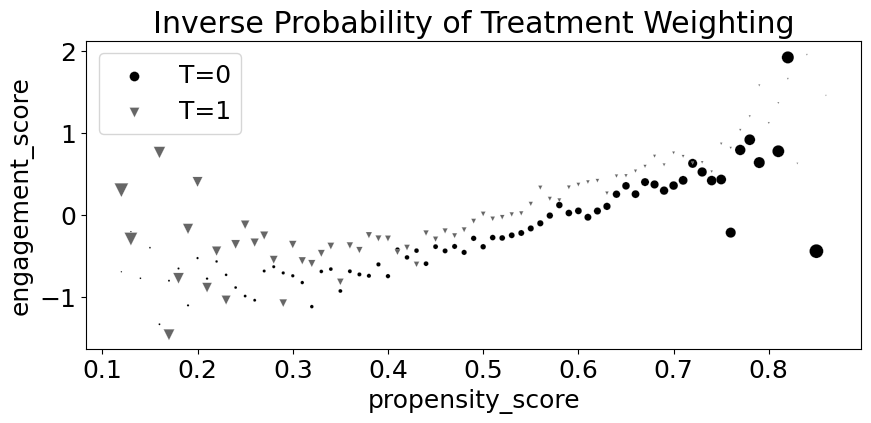

In [25]:
marker = ['o', 'v', 'd', 'p']

g_data = (data_ps
          .assign(
              weight = data_ps["intervention"]/data_ps["propensity_score"] + (1-data_ps["intervention"])/(1-data_ps["propensity_score"]),
              propensity_score=data_ps["propensity_score"].round(2)
          )
          .groupby(["propensity_score", "intervention"])
          [["weight", "engagement_score"]]
          .mean()
          .reset_index())

plt.figure(figsize=(10,4))
for t in [0, 1]:
    sns.scatterplot(data=g_data.query(f"intervention=={t}"), y="engagement_score", x="propensity_score", size="weight",
                    sizes=(1,100), color=color[t], legend=None, label=f"T={t}", marker=marker[t])

plt.title("Inverse Probability of Treatment Weighting")
plt.legend();

### The IPW Estimate

$$\widehat{ATE} = E\left[\frac{T\,Y}{\hat{e}(X)}\right] - E\left[\frac{(1 - T)\,Y}{1 - \hat{e}(X)}\right]$$

- Each expectation is a weighted sum divided by $N$, the whole sample

In [26]:
weight_t = 1/data_ps.query("intervention==1")["propensity_score"]
weight_nt = 1/(1-data_ps.query("intervention==0")["propensity_score"])
t1 = data_ps.query("intervention==1")["engagement_score"]
t0 = data_ps.query("intervention==0")["engagement_score"]

y1 = sum(t1*weight_t)/len(data_ps)
y0 = sum(t0*weight_nt)/len(data_ps)

print("E[Y1]:", y1)
print("E[Y0]:", y0)
print("ATE", y1 - y0)

E[Y1]: 0.11656317232946703
E[Y0]: -0.14941553647814357
ATE 0.2659787088076106


### One Line Version

- About $0.27$ again, right next to regression


- The two terms combine into a single average:

$$\widehat{ATE} = E\left[Y\,\frac{T - \hat{e}(X)}{\hat{e}(X)\big(1 - \hat{e}(X)\big)}\right]$$

In [27]:
np.mean(data_ps["engagement_score"]
        * (data_ps["intervention"] - data_ps["propensity_score"])
        / (data_ps["propensity_score"]*(1-data_ps["propensity_score"])))

np.float64(0.2659787088076108)

### Regression and IPW

- Regression recovers the effect as
$$\tau_{ols} = \frac{E\big[Y\,(T - E[T \mid X])\big]}{E\big[\mathrm{Var}(T \mid X)\big]}$$
- A binary $T$ has $\mathrm{Var}(T \mid X) = e(X)\big(1 - e(X)\big)$, so IPW is
$$\tau_{ipw} = E\left[\frac{Y\,(T - E[T \mid X])}{\mathrm{Var}(T \mid X)}\right]$$
- Same pieces. IPW gives every group's effect weight $1$
- Regression weights each group by its treatment variance, as we saw in the regression lecture

### Variance of IPW

- No simple standard error formula, so <b style="color:#73000A;">bootstrap</b> it
- Resample rows with replacement, refit the score, recompute the ATE, repeat
- The $2.5$th and $97.5$th percentiles of the estimates give a $95\%$ interval
- Refit the score inside every round. Its noise is part of the estimate's noise

In [28]:
from sklearn.linear_model import LogisticRegression
from patsy import dmatrix

# define function that computes the IPW estimator
def est_ate_with_ps(df, ps_formula, T, Y):

    X = dmatrix(ps_formula, df)
    ps_model = LogisticRegression(penalty=None,
                                  max_iter=1000).fit(X, df[T])
    ps = ps_model.predict_proba(X)[:, 1]

    # compute the ATE
    return np.mean((df[T]-ps) / (ps*(1-ps)) * df[Y])

formula = '''tenure + last_engagement_score + department_score
+ C(n_of_reports) + C(gender) + C(role)'''
T = "intervention"
Y = "engagement_score"

est_ate_with_ps(df, formula, T, Y)

np.float64(0.2659172829575647)

### Sidebar: `predict_proba` and `partial`

- sklearn's `predict` returns $0$ or $1$. `predict_proba` returns two columns, $P(T = 0 \mid X)$ and $P(T = 1 \mid X)$
- We want the second one, hence `[:, 1]`
- `partial` fixes some arguments of a function and returns a new function
- The bootstrap wants a function of the data alone, so we fix the formula, $T$ and $Y$

In [29]:
from joblib import Parallel, delayed # for parallel processing
from toolz import partial

def bootstrap(data, est_fn, rounds=200, seed=123, pcts=[2.5, 97.5]):
    np.random.seed(seed)

    stats = Parallel(n_jobs=4)(
        delayed(est_fn)(data.sample(frac=1, replace=True))
        for _ in range(rounds)
    )

    return np.percentile(stats, pcts)

print(f"ATE: {est_ate_with_ps(df, formula, T, Y)}")

est_fn = partial(est_ate_with_ps, ps_formula=formula, T=T, Y=Y)
print(f"95% C.I.: ", bootstrap(df, est_fn))

ATE: 0.2659172829575647
95% C.I.:  [0.22656706 0.30071832]


### Where the Variance Comes From

- This interval is about as wide as the regression one
- It widens when a few units carry <b style="color:#73000A;">big weights</b>, because a few units then drive the answer
- Big weights come from treated units at low $\hat{e}(X)$ or untreated units at high $\hat{e}(X)$
- Few of those means few units to build $Y_1$ for the untreated or $Y_0$ for the treated

### Practical Example: Causal Contextual Bandits

- A contextual bandit learns which treatment to give each user, and keeps exploring while it does
- Its data is confounded by design, since it assigns treatments it expects to work
- If it assigns at random with known probabilities, it can store each one. That is $e(X)$
- Reweight the logged data by those probabilities and the confounding comes out

### Stabilized Propensity Weights

- Weighting the treated by $1 / P(T = 1 \mid X)$ builds a pseudo population as if <b style="color:#73000A;">everyone</b> were treated
- So the treated weights sum to about $N$, the full sample size. Same for the untreated
- This is importance sampling: data drawn from $P(T = 1 \mid X)$, reweighted toward $P(T = 1) = 1$

In [30]:
print("Original Sample Size", data_ps.shape[0])
print("Treated Pseudo-Population Sample Size", sum(weight_t))
print("Untreated Pseudo-Population Sample Size", sum(weight_nt))

Original Sample Size 10391
Treated Pseudo-Population Sample Size 10435.089079197922
Untreated Pseudo-Population Sample Size 10354.298899788306


### Stabilize with the Marginal

- A rare treatment gives a tiny $P(T = t \mid X)$ and a huge weight
- Put the marginal probability on top:
$$w = \frac{P(T = t)}{P(T = t \mid X)}$$
- This rescales the weights within each treatment group. The ATE stays the same...

In [31]:
p_of_t = data_ps["intervention"].mean()

t1 = data_ps.query("intervention==1")
t0 = data_ps.query("intervention==0")

weight_t_stable = p_of_t/t1["propensity_score"]
weight_nt_stable = (1-p_of_t)/(1-t0["propensity_score"])

print("Treat size:", len(t1))
print("W treat", sum(weight_t_stable))

print("Control size:", len(t0))
print("W control", sum(weight_nt_stable))

Treat size: 5611
W treat 5634.807508745983
Control size: 4780
W control 4763.116999421417


In [32]:
nt = len(t1)
nc = len(t0)

y1 = sum(t1["engagement_score"]*weight_t_stable)/nt
y0 = sum(t0["engagement_score"]*weight_nt_stable)/nc

print("ATE: ", y1 - y0)

ATE:  0.26597870880761065


### Pseudo Populations

- Under random assignment $P(T \mid X) = P(T)$: nobody's covariates change their odds
- Here managers with engaged teams were likelier to train, so the treated $\hat{e}(X)$ sits to the right
- Weighting lifts treated units at low $\hat{e}(X)$ and controls at high $\hat{e}(X)$
- After weighting the two distributions <b style="color:#73000A;">line up</b>. Assignment looks random, given no unobserved confounders
- That answers the earlier objection: two managers with the same score can differ, but the weighted <b style="color:#73000A;">groups</b> balance

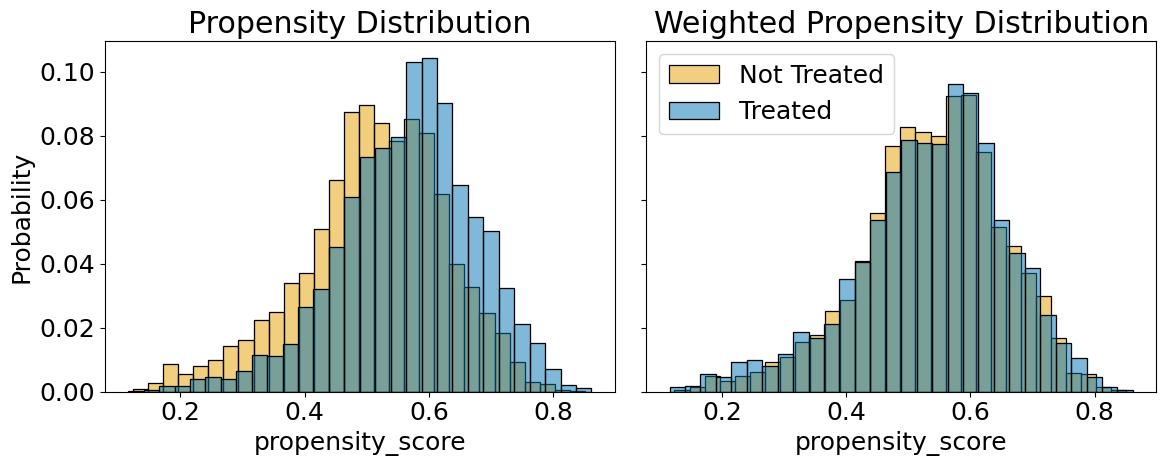

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5), sharex=True, sharey=True)

sns.histplot(data_ps.query("intervention==0")["propensity_score"], stat="probability",
             label="Not Treated", color="#E69F00", bins=30, ax=ax1, alpha=0.5)
sns.histplot(data_ps.query("intervention==1")["propensity_score"], stat="probability",
             label="Treated", color="#0072B2", alpha=0.5, bins=30, ax=ax1)
ax1.set_title("Propensity Distribution")

sns.histplot(data_ps.query("intervention==0").assign(w=weight_nt_stable),
             x="propensity_score", stat="probability",
             color="#E69F00", weights="w", label="Not Treated", bins=30, ax=ax2,  alpha=0.5)

sns.histplot(data_ps.query("intervention==1").assign(w=weight_t_stable),
             x="propensity_score", stat="probability",
             color="#0072B2", weights="w", label="Treated", bins=30, alpha=0.5, ax=ax2)
ax2.set_title("Weighted Propensity Distribution")
plt.legend()

plt.tight_layout()

### Selection into the Sample

- The managers selected into treatment. Everyone was still in the data, we just could not compare them directly
- Here the selection is into the data itself like a survey. Some people never show up, so we have no outcome for them
- IPW handles this too. It began as the <b style="color:#73000A;">Horvitz Thompson</b> estimator, 1952
- Survey your users and some do not answer. If the unhappy ones skip it, the average is too high
- Model $P(R = 1 \mid X)$, the chance of responding, and weight respondents by $1 / P(R = 1 \mid X)$
- Respondents who look like nonrespondents then speak for them
- With confounding and selection together, multiply, and stabilize the treatment part:
$$W = \frac{P(T = t)}{P(R = 1 \mid X)\,P(T = t \mid X)}$$

## Bias Variance Trade Off

- A better model of $T$ does not mean a better effect estimate
- A variable that predicts $T$ but does not cause $Y$ is a noise inducing control, as in the regression lecture
- A perfect model gives every treated unit $\hat{e} \approx 1$ and every control $\hat{e} \approx 0$, so nothing is left to compare
- Under randomization $\hat{e}(X)$ predicts nothing, and that is the best case for estimation
- Model $T$ well enough to remove the bias, and no better

### Sidebar: Trimming

- Keep $\hat{e}(X)$ above a floor such as $1\%$, so no weight passes $100$
- Or clip the weights directly
- The estimate is no longer unbiased, but its mean squared error can be lower

## Positivity

- Adding variables to the score makes conditional independence more believable
- It also pushes the treated toward high $\hat{e}(X)$ and the controls toward low, so positivity gets worse
- With no treated units at low $\hat{e}(X)$, no reweighting can rebuild $Y_1$ there


- The villages showed this with nine rows. Here is a simulation where the true ATE is $1$
- Higher $x$ lowers $Y$ and raises the chance of treatment, so the naive comparison is biased down

In [34]:
np.random.seed(1)

n = 1000
x = np.random.normal(0, 1, n)
t = np.random.normal(x, 0.5, n) > 0

y0 = -x
y1 = y0 + t  # ate of 1

y = np.random.normal((1-t)*y0 + t*y1, 0.2)

df_no_pos = pd.DataFrame(dict(x=x,t=t.astype(int),y=y))

df_no_pos.head()

,x,t,y
0,1.624345,1,-0.526442
1,-0.611756,0,0.659516
2,-0.528172,0,0.438549
3,-1.072969,0,0.950810
4,0.865408,1,-0.271397


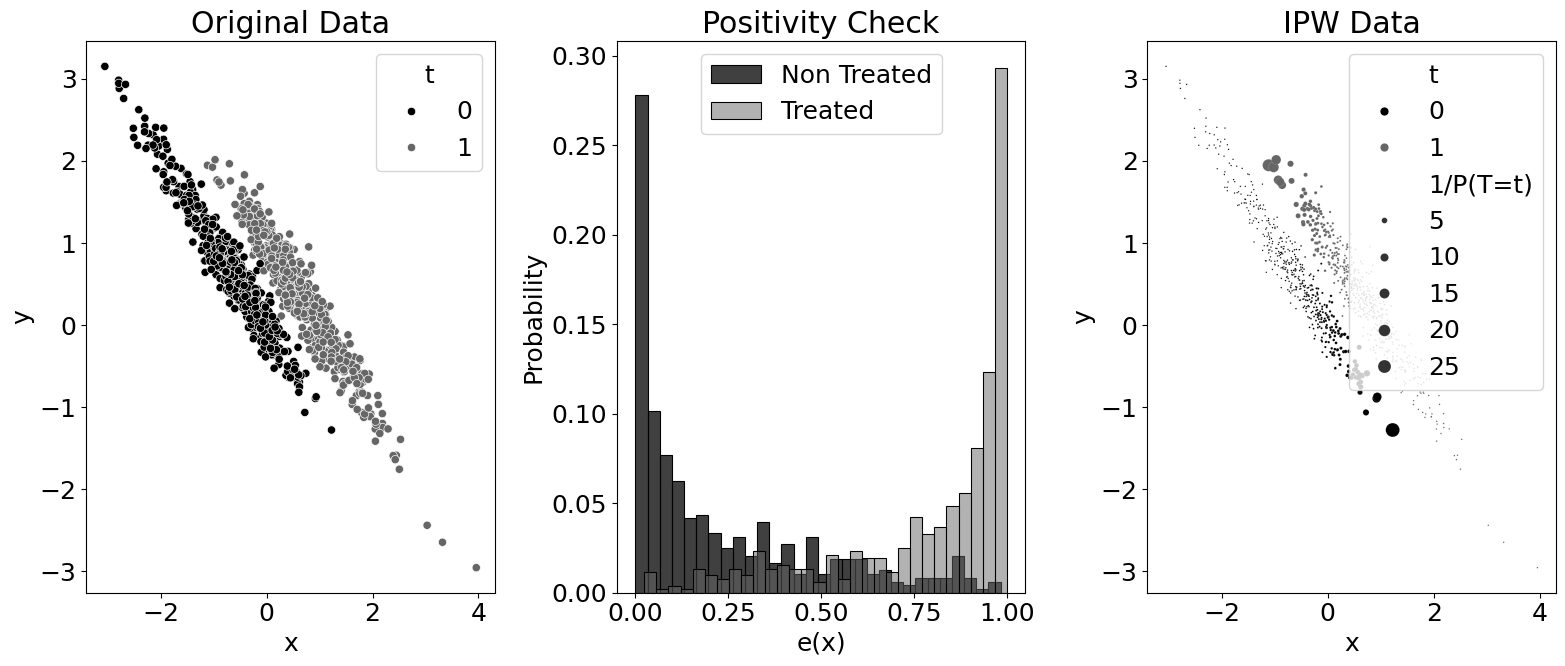

In [35]:
ps_model_sim = smf.logit('''t ~ x''', data=df_no_pos).fit(disp=0)
df_no_pos_ps = df_no_pos.assign(ps=ps_model_sim.predict(df_no_pos))

ps = ps_model_sim.predict(df_no_pos)
w = df_no_pos["t"]*df_no_pos["t"].mean()/ps  + (1-df_no_pos["t"])*((1-df_no_pos["t"].mean())/(1-ps))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16,7))

sns.scatterplot(data=df_no_pos_ps.assign(w=w), x="x", y="y", hue="t", ax=ax1);
ax1.set_title("Original Data")

sns.histplot(df_no_pos_ps.query("t==0")["ps"], stat="probability",
             label="Non Treated", color="C0", bins=30, ax=ax2)
sns.histplot(df_no_pos_ps.query("t==1")["ps"], stat="probability",
             label="Treated", color="C1", alpha=0.5, bins=30, ax=ax2)
ax2.set_xlabel("e(x)")
ax2.legend()
ax2.set_title("Positivity Check")

sns.scatterplot(data=df_no_pos_ps.assign(**{"1/P(T=t)":w}), x="x", y="y", hue="t", ax=ax3, size="1/P(T=t)", sizes=(1, 100));
ax3.set_title("IPW Data")

plt.tight_layout()

### Reading the Three Panels

- Middle: most controls sit near $\hat{e} = 0$, where there are almost no treated units
- Right: the few controls at high $\hat{e}$ and treated at low $\hat{e}$ carry huge weights
- No overlap plus huge weights. Now the estimate

In [36]:
est_fn = partial(est_ate_with_ps, ps_formula="x", T="t", Y="y")
print("ATE:",  est_fn(df_no_pos))
print(f"95% C.I.: ", bootstrap(df_no_pos, est_fn))

ATE: 0.6483491345012087
95% C.I.:  [0.41730173 0.88892041]


### IPW Misses, Regression Does Not

- The whole interval sits below the true $1$, so this is bias as well as noise
- IPW at least shows the problem: the middle panel is a positivity check you can see
- Regression <b style="color:#73000A;">extrapolates</b> into the empty regions. Here the line is right, so it gets $1$
- Regression trades positivity for an assumption about the shape of $E[Y \mid T, X]$

In [37]:
smf.ols("y ~ x + t", data=df_no_pos).fit().params["t"]

np.float64(1.016585548767948)

## Two Approaches to Adjusting for Confounding

- **Outcome regression:** Model how $X$ predicts $Y$, then compare predicted outcomes under treatment and no treatment.
- **Propensity-score weighting:** Model how $X$ predicts treatment, then reweight the groups to make their covariates comparable.
- Both rely on **selection on observables** and sufficient **overlap**.
- The difference is which relationship we model: **the outcome** or **treatment assignment**.

Which relationship can we model more credibly?

## Doubly Robust Estimation

Use an outcome model and a propensity score. Only one needs to be correctly specified.

- **Fit the treated outcome model:** Using treated observations, model $Y$ as a function of $X$.
- **Predict for everyone:** $\hat{m}_1(X_i)$ predicts unit $i$’s outcome **if treated**, whether or not it actually received treatment.
   - For t=1, train on the treated and predict on the entire data
- **Correct using observed outcomes:** For treated units, calculate $Y_i-\hat{m}_1(X_i)$ and weight these prediction errors by $1/\hat{e}(X_i)$.

$$
\hat{\mu}_1^{DR}
=
\underbrace{\frac{1}{N}\sum_i \hat{m}_1(X_i)}_{\text{average predicted outcome if everyone were treated}}
+
\underbrace{\frac{1}{N}\sum_i \frac{T_i}{\hat{e}(X_i)}
\big(Y_i-\hat{m}_1(X_i)\big)}_{\text{weighted correction using treated observations}}
$$

### Repeat for the Untreated Outcome

- Fit a second outcome model using **untreated observations**.
- Predict for everyone: $\hat{m}_0(X_i)$ predicts unit $i$’s outcome **without treatment**.
- Correct using untreated observations, weighted by $1/[1-\hat{e}(X_i)]$.

$$
\hat{\mu}_0^{DR}
=
\frac{1}{N}\sum_i \hat{m}_0(X_i)
+
\frac{1}{N}\sum_i \frac{1-T_i}{1-\hat{e}(X_i)}
\big(Y_i-\hat{m}_0(X_i)\big)
$$

The estimated average treatment effect is:

$$
\widehat{ATE}^{DR}=\hat{\mu}_1^{DR}-\hat{\mu}_0^{DR}
$$

If the outcome models are correct, the corrections average to zero in expectation.

### Two Chances to Be Right

- Rearrange the same estimator:

$$
\hat{\mu}_1^{DR}
=
\underbrace{\frac{1}{N}\sum_i \frac{T_iY_i}{\hat{e}(X_i)}}_{\text{IPW estimate}}
+
\underbrace{\frac{1}{N}\sum_i
\frac{\hat{e}(X_i)-T_i}{\hat{e}(X_i)}
\,\hat{m}_1(X_i)}_{\text{outcome-model adjustment}}
$$

- If the propensity model is correct, the adjustment is zero in expectation, leaving IPW.
- Repeat for the untreated outcome, then subtract: $\widehat{ATE}^{DR} = \hat{\mu}_1^{DR} - \hat{\mu}_0^{DR}$.
- In code: a logit for $\hat{e}$ and one outcome regression per group, each predicting for everyone.

In [38]:
from sklearn.linear_model import LinearRegression

def doubly_robust(df, formula, T, Y):
    X = dmatrix(formula, df)

    ps_model = LogisticRegression(penalty=None,
                                  max_iter=1000).fit(X, df[T])
    ps = ps_model.predict_proba(X)[:, 1]

    m0 = LinearRegression().fit(X[df[T]==0, :], df.query(f"{T}==0")[Y])
    m1 = LinearRegression().fit(X[df[T]==1, :], df.query(f"{T}==1")[Y])

    m0_hat = m0.predict(X)
    m1_hat = m1.predict(X)

    return (
        np.mean(df[T]*(df[Y] - m1_hat)/ps + m1_hat) -
        np.mean((1-df[T])*(df[Y] - m0_hat)/(1-ps) + m0_hat)
    )

In [39]:
print("DR ATE:", doubly_robust(df, formula, T, Y))

est_fn = partial(doubly_robust, formula=formula, T=T, Y=Y)
print("95% CI", bootstrap(df, est_fn))

DR ATE: 0.2712100766069552
95% CI [0.23013748 0.30521421]


### Treatment Is Easy to Model

- On the training data DR agrees with everything else. That is reassuring and not very informative
- So build data where one model is easy and the other is hard
- First case: $e(x) = 1 / \big(1 + e^{-(1 + 1.5x)}\big)$, exactly a logit, so the score is easy
- The outcome is curved in $x$ for the controls, so a straight line will miss it. True ATE about $2$

In [40]:
np.random.seed(123)

n = 10000
x = np.random.beta(1,1, n).round(2)*2
e = 1/(1+np.exp(-(1+1.5*x)))
t = np.random.binomial(1, e)

y1 = 1
y0 = 1 - 1*x**3
y = t*(y1) + (1-t)*y0 + np.random.normal(0, 1, n)

df_easy_t = pd.DataFrame(dict(y=y, x=x, t=t))

print("True ATE:", np.mean(y1-y0))

True ATE: 2.0056243152


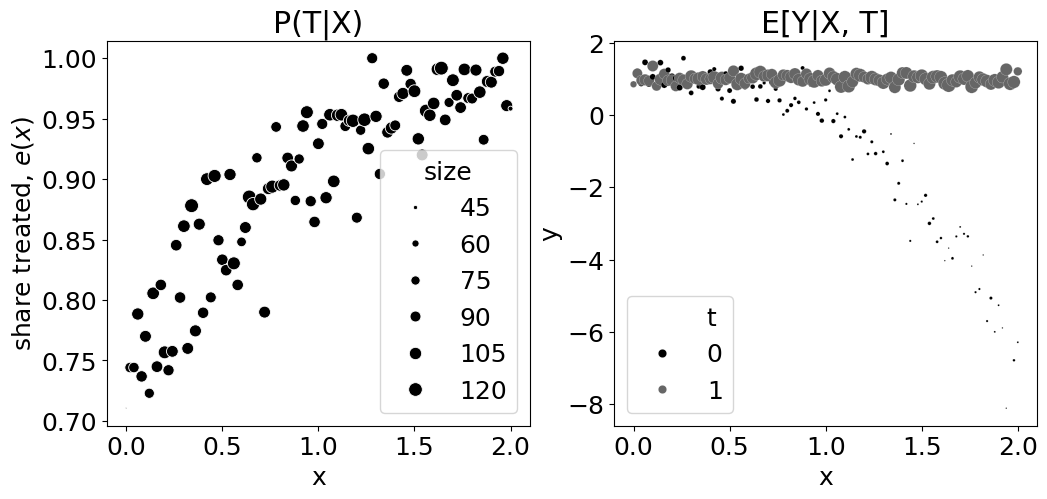

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))

sns.scatterplot(data=(df_easy_t
                      .assign(size=1)
                      .groupby(["x"])
                      .agg({"size":"sum", "t":"mean"})
                      .reset_index()),
                x="x", y="t", sizes=(1, 100), size="size", ax=ax1);
ax1.set_title("P(T|X)")
ax1.set_ylabel("share treated, $e(x)$")

sns.scatterplot(data=(df_easy_t
                      .assign(size=1)
                      .groupby(["x", "t"])
                      .agg({"size":"sum", "y":"mean"})
                      .reset_index()),
                x="x", y="y", hue="t", sizes=(1, 100), size="size", ax=ax2)

ax2.set_title("E[Y|X, T]")

h,l = ax2.get_legend_handles_labels()
plt.legend(h[0:3],l[0:3]);

### Regression Misses the Curve

- The effect is zero at low $x$ and grows fast as $x$ rises
- One line per group, then average the gap in predictions over everyone

In [42]:
m0 = smf.ols("y~x", data=df_easy_t.query("t==0")).fit()
m1 = smf.ols("y~x", data=df_easy_t.query("t==1")).fit()
regr_ate = (m1.predict(df_easy_t) - m0.predict(df_easy_t)).mean()

print("Regression ATE:", regr_ate)

Regression ATE: 1.7866783968330215


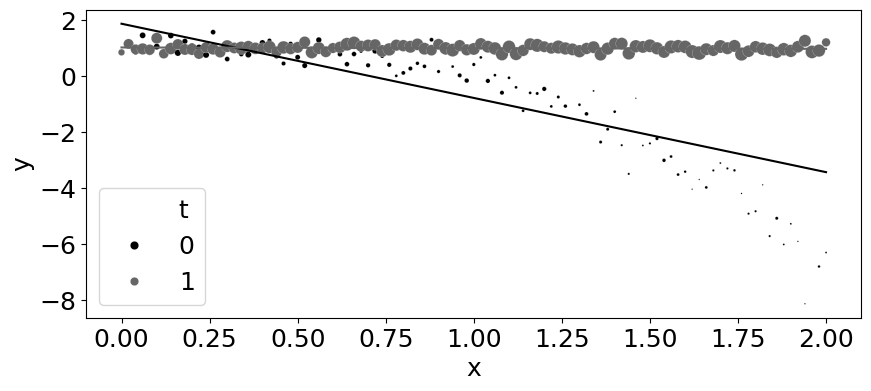

In [43]:
regr = smf.ols("y~x*t", data=df_easy_t).fit()

plt.figure(figsize=(10,4))

sns.scatterplot(data=(df_easy_t
                      .assign(count=1)
                      .groupby(["x", "t"])
                      .agg({"count":"sum", "y":"mean"})
                      .reset_index()),
                x="x", y="y", hue="t", sizes=(1, 100), size="count");

g = sns.lineplot(data=(df_easy_t
                   .assign(pred=regr.fittedvalues)
                   .groupby(["x", "t"])
                   .mean()
                   .reset_index()),
             x="x", y="pred", hue="t", sizes=(1, 100))

h,l = g.get_legend_handles_labels()
plt.legend(h[0:3],l[0:3]);

### With the Right Shape, Regression Works

- Add the cube and regression recovers $2$
- That needs us to know the cube is there. With real data we usually would not

In [44]:
m = smf.ols("y~t*(x + np.power(x, 3))", data=df_easy_t).fit()
regr_ate = (m.predict(df_easy_t.assign(t=1))
            - m.predict(df_easy_t.assign(t=0))).mean()

print("Regression ATE:", regr_ate)

Regression ATE: 1.997099974718984


### IPW and DR

- The score is a plain logit, so IPW should do well
- DR uses the same wrong straight line outcome model, plus the right score

In [45]:
est_fn = partial(est_ate_with_ps, ps_formula="x", T="t", Y="y")
print("Propensity Score ATE:", est_fn(df_easy_t))
print("95% CI", bootstrap(df_easy_t, est_fn))

Propensity Score ATE: 2.0000995686479537
95% CI [1.81133665 2.22613056]


In [46]:
est_fn = partial(doubly_robust, formula="x", T="t", Y="y")
print("DR ATE:", est_fn(df_easy_t))
print("95% CI", bootstrap(df_easy_t, est_fn))

DR ATE: 2.0010131305548926
95% CI [1.87190613 2.14533967]


### What Happened

- IPW lands on $2$
- DR lands on $2$ too, with a <b style="color:#73000A;">narrower</b> interval than IPW, even though its outcome model is wrong

### Outcome Is Easy to Model

- Now flip it: $P(T \mid X)$ is curved and $E[Y_t \mid X]$ is a straight line
- True ATE is $-1$

In [47]:
np.random.seed(123)

n = 10000
x = np.random.beta(1,1, n).round(2)*2
e = 1/(1+np.exp(-(2*x - x**3)))
t = np.random.binomial(1, e)

y1 = x
y0 = y1 + 1 # ate of -1
y = t*(y1) + (1-t)*y0 + np.random.normal(0, 1, n)

df_easy_y = pd.DataFrame(dict(y=y, x=x, t=t))

print("True ATE:", np.mean(y1-y0))

True ATE: -1.0


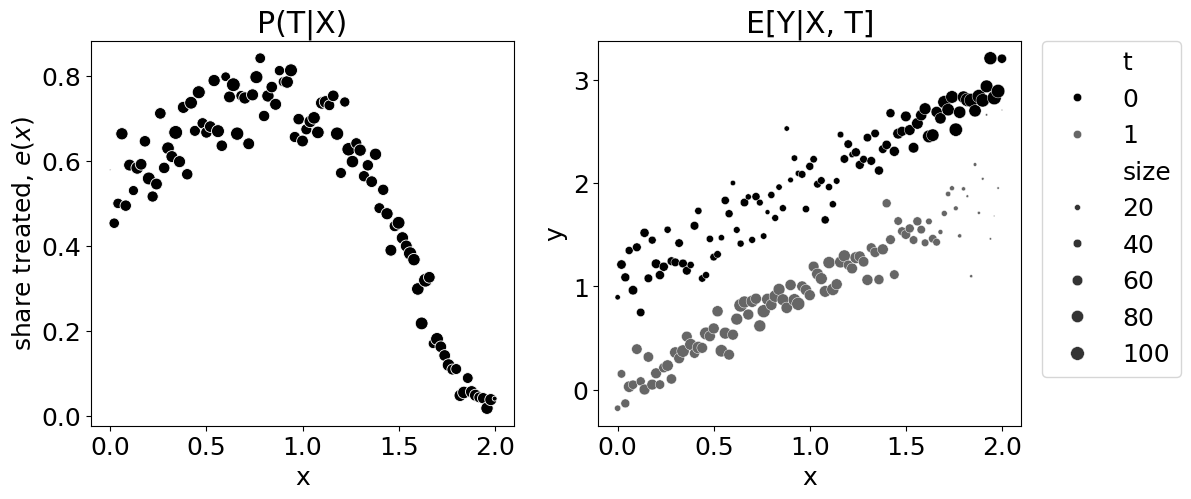

In [48]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))

sns.scatterplot(data=(df_easy_y
                      .assign(size=1)
                      .groupby(["x"])
                      .agg({"size":"sum", "t":"mean"})
                      .reset_index()),
                x="x", y="t", sizes=(1, 100), size="size", ax=ax1, legend=None);

sns.scatterplot(data=(df_easy_y
                      .assign(size=1)
                      .groupby(["x", "t"])
                      .agg({"size":"sum", "y":"mean"})
                      .reset_index()),
                x="x", y="y", hue="t", sizes=(1, 100), size="size", ax=ax2);

ax1.set_title("P(T|X)")
ax1.set_ylabel("share treated, $e(x)$")
ax2.set_title("E[Y|X, T]")

plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.);

In [49]:
est_fn = partial(est_ate_with_ps, ps_formula="x", T="t", Y="y")
print("Propensity Score ATE:", est_fn(df_easy_y))
print("95% CI", bootstrap(df_easy_y, est_fn))

Propensity Score ATE: -1.1042787799722575
95% CI [-1.14324543 -1.06578745]


In [50]:
m0 = smf.ols("y~x", data=df_easy_y.query("t==0")).fit()
m1 = smf.ols("y~x", data=df_easy_y.query("t==1")).fit()
regr_ate = (m1.predict(df_easy_y) - m0.predict(df_easy_y)).mean()

print("Regression ATE:", regr_ate)

Regression ATE: -1.0008783612504335


In [51]:
est_fn = partial(doubly_robust, formula="x", T="t", Y="y")
print("DR ATE:", est_fn(df_easy_y))
print("95% CI", bootstrap(df_easy_y, est_fn))

DR ATE: -1.002845858106496
95% CI [-1.04156013 -0.96353435]


### Two Shots at Being Right

- IPW misses: its interval excludes $-1$. Regression and DR both hit it
- Sometimes $P(T \mid X)$ is the easy model and sometimes $E[Y_t \mid X]$ is. DR only needs one
- This is one DR estimator among many. Plain linear regression is one too, with $e(x) = \beta x$, which is not kept between $0$ and $1$
- More: Robins and coauthors (2008), on DR estimators when the weights are highly variable

## Generalized Propensity Score for Continuous Treatment

- With a continuous $T$ there are infinitely many potential outcomes $Y_t$
- And $P(T = t \mid X) = 0$ for any single value, so there is no score to invert
- One fix: cut $T$ into bins and treat it as discrete
- The other: the <b style="color:#73000A;">generalized propensity score</b>, which uses a density in place of the probability

### Interest Rates and Loan Duration

- A bank wants to know how a loan's interest rate affects how long customers take to repay
- High rates should push people to repay faster, so the effect should be <b style="color:#73000A;">negative</b>
- Rates were set by two models, `ml_1` and `ml_2`, plus random noise. The noise protects positivity
- Naive regression says the effect is positive, which makes no business sense

In [52]:
df_cont_t = pd.read_csv("data/interest_rate.csv")

df_cont_t.head()

,ml_1,ml_2,interest,duration
0,0.392938,0.326285,7.1,12.0
1,-0.427721,0.679573,5.6,17.0
2,-0.546297,0.647309,11.1,12.0
3,0.102630,-0.264776,7.2,18.0
4,0.438938,-0.648818,9.5,19.0


In [53]:
m_naive = smf.ols("duration ~ interest", data=df_cont_t).fit()
m_naive.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,14.5033,0.226,64.283,0.000,14.061,14.946
interest,0.3393,0.029,11.697,0.000,0.282,0.396


### Building the Score

- Use the conditional density $f(t \mid X)$ in place of $P(T = t \mid X)$
- Assume $T \sim N(\mu_i, \sigma^2)$, with one $\sigma$ for everyone:
$$f(t_i) = \frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{1}{2}\left(\frac{t_i - \mu_i}{\sigma}\right)^2\right)$$
- Regress $T$ on $X$ with OLS. Fitted values give $\mu_i$, the residual standard deviation gives $\sigma$
- Evaluate that density at each unit's actual rate. Weight by $1 / f$
- Not normal? Fit a GLM instead, for example a Poisson, and use its probability mass

In [54]:
from scipy.stats import norm

model_t = smf.ols("interest~ml_1+ml_2", data=df_cont_t).fit()

gps = norm(loc=model_t.fittedvalues,
           scale=np.std(model_t.resid)).pdf(df_cont_t["interest"])

final_model = smf.wls("duration~interest",
                      data=df_cont_t, weights=1/gps).fit()

final_model.params["interest"]

np.float64(-0.6673977919925864)

### Why the Weights Blow Up

- Negative now, about $-0.67$. The data is simulated and the true effect is $-0.8$
- An unlikely rate means a big residual in the treatment model, and the weight grows exponentially with it
- The plot fits the rate on `ml_1` only, so it fits in one picture. Some weights pass $1{,}000$
- A handful of points do almost all the work, so the variance is large

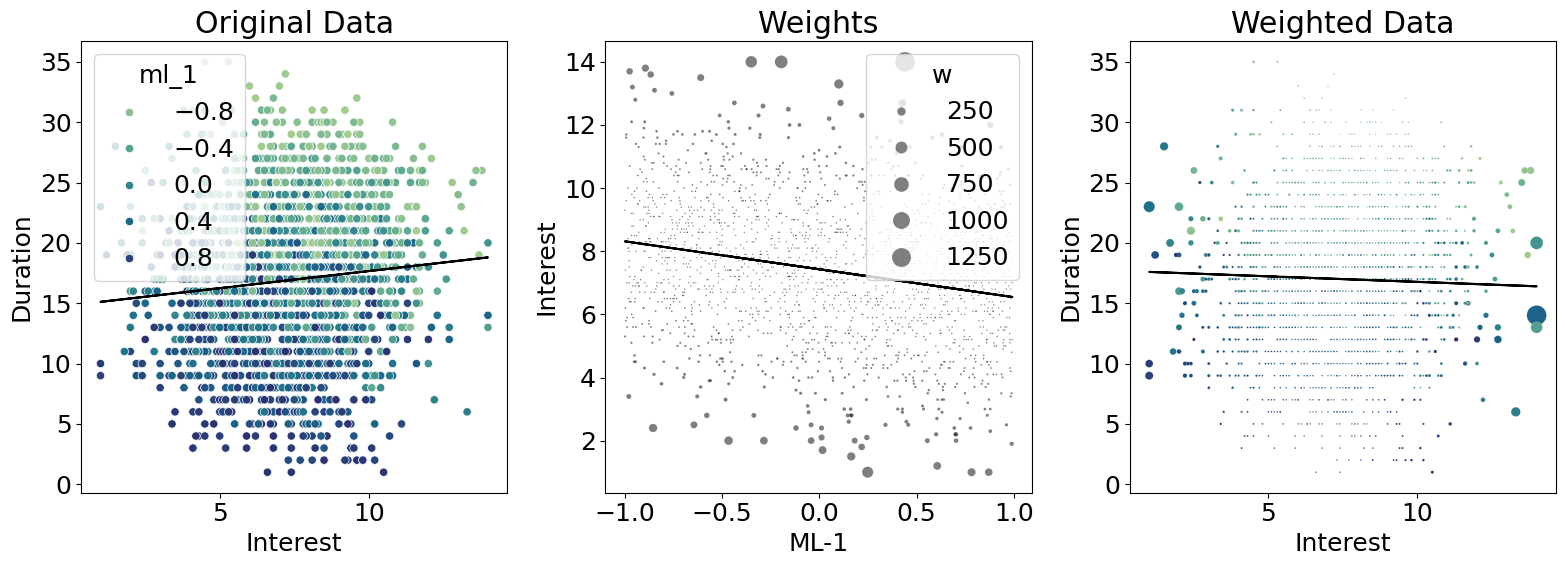

In [55]:
np.random.seed(1)
sample = df_cont_t.sample(2000)

model_ex = smf.ols("interest~ml_1", data=sample).fit()
gps_ex = norm(loc=model_ex.fittedvalues, scale=np.std(model_ex.resid)).pdf(sample["interest"])

w_ex = 1/gps_ex

m = smf.ols("duration~interest", data=sample).fit()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 6))

sns.scatterplot(data=sample, x="interest", y="duration", alpha=1, ax=ax1, hue="ml_1", palette = 'crest')
ax1.plot(sample["interest"], m.fittedvalues)

ax1.set_ylabel("Duration")
ax1.set_xlabel("Interest")
ax1.set_title("Original Data");


sns.scatterplot(data=sample.assign(w=w_ex), x="ml_1", y="interest",size="w",
                sizes=(1,200), alpha=0.5, ax=ax2)
ax2.plot(sample["ml_1"], model_ex.fittedvalues)
ax2.set_ylabel("Interest")
ax2.set_xlabel("ML-1")
ax2.set_title("Weights")


m = smf.wls("duration~interest", data=sample, weights=w_ex).fit()

sns.scatterplot(data=sample.assign(w=w_ex), x="interest", y="duration",size="w",
                sizes=(1,200), alpha=1, ax=ax3, hue="ml_1", legend=None, palette = 'crest')
ax3.plot(sample["interest"], m.fittedvalues)
ax3.set_ylabel("Duration")
ax3.set_xlabel("Interest")
ax3.set_title("Weighted Data")

plt.tight_layout()

### Stabilize, and Here It Matters

- Put the marginal density $f(t)$ on top, using the average rate as its mean
- Points far from the fitted line still gain weight. Points far from the average rate now lose some
- The weights sum to about the sample size again
- With a discrete $T$ stabilizing was optional. With a continuous $T$, do it

In [56]:
stabilizer = norm(
    loc=df_cont_t["interest"].mean(),
    scale=np.std(df_cont_t["interest"] - df_cont_t["interest"].mean())
).pdf(df_cont_t["interest"])

gipw =  stabilizer/gps

print("Original Sample Size:", len(df_cont_t))
print("Effective Stable Weights Sample Size:", sum(gipw))

Original Sample Size: 10000
Effective Stable Weights Sample Size: 9988.19595174861


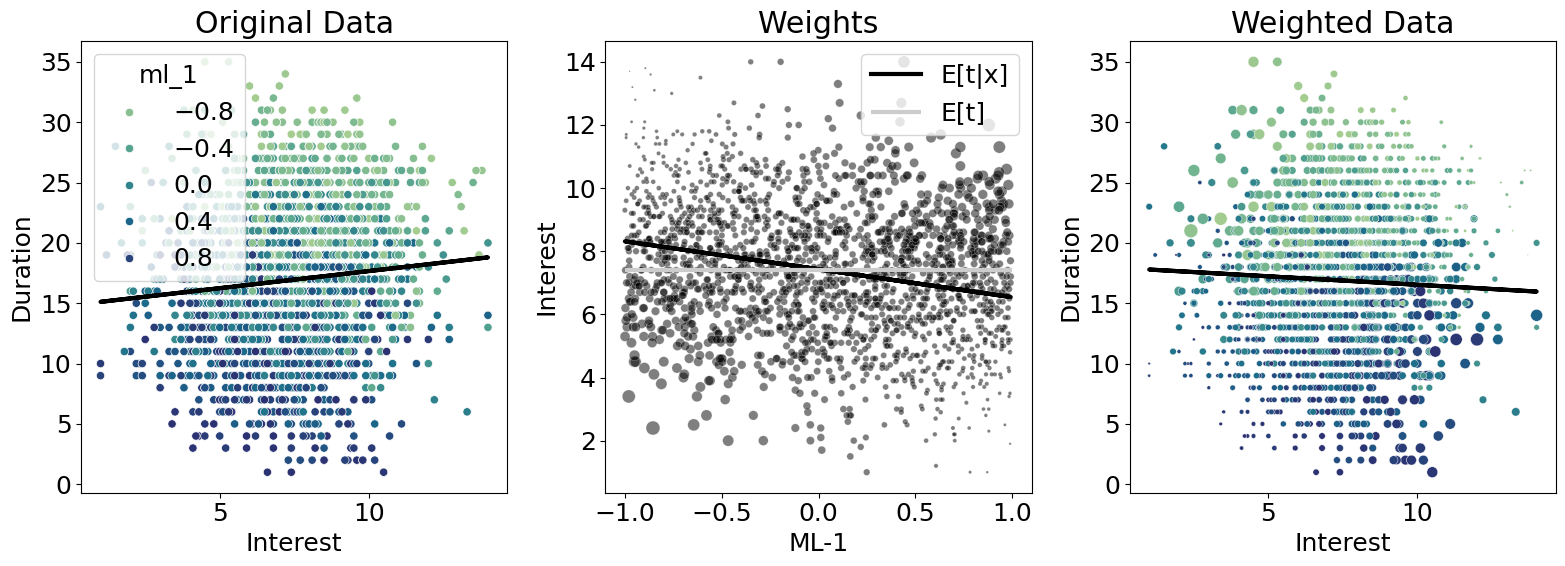

In [57]:
np.random.seed(1)
sample = df_cont_t.sample(2000)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 6))

model_ex = smf.ols("interest~ml_1", data=sample).fit()
gps_ex = norm(loc=model_ex.fittedvalues, scale=np.std(model_ex.resid)).pdf(sample["interest"])
stabilizer_ex = norm(
    loc=sample["interest"].mean(),
    scale=np.std(sample["interest"] - sample["interest"].mean())
).pdf(sample["interest"])


w_ex = stabilizer_ex/gps_ex

m = smf.ols("duration~interest", data=sample).fit()

sns.scatterplot(data=sample, x="interest", y="duration", alpha=1, ax=ax1, hue="ml_1", palette = 'crest')
ax1.plot(sample["interest"], m.fittedvalues, lw=3)
ax1.set_ylabel("Duration")
ax1.set_xlabel("Interest")
ax1.set_title("Original Data");


sns.scatterplot(data=sample.assign(w=w_ex), x="ml_1", y="interest",size="w",
                sizes=(1,100), alpha=0.5, ax=ax2)

ax2.plot(sample["ml_1"], model_ex.fittedvalues, label="E[t|x]", lw=3)

ax2.hlines(sample["interest"].mean(), -1, 1, label="E[t]", color="C2", lw=3)
ax2.set_ylabel("Interest")
ax2.set_xlabel("ML-1")
ax2.set_title("Weights")

h,l = ax2.get_legend_handles_labels()
ax2.legend(h[5:],l[5:],)

m = smf.wls("duration~interest", data=sample, weights=w_ex).fit()

sns.scatterplot(data=sample.assign(w=w_ex), x="interest", y="duration",size="w",
                sizes=(1,100), alpha=1, ax=ax3, hue="ml_1", legend=None, palette = 'crest')
ax3.plot(sample["interest"], m.fittedvalues, lw=3)
ax3.set_ylabel("Duration")
ax3.set_xlabel("Interest")
ax3.set_title("Weighted Data")

plt.tight_layout()

### Closer, and Tighter

- The stabilized estimate is about $-0.78$, near the true $-0.8$
- Both bootstrap intervals contain $-0.8$. The stabilized one is much narrower
- Other routes: Hirano and Imbens put the score in a regression; Imai and van Dyk segment on fitted $T$. The `causal-curve` package implements some of these

In [58]:
final_model = smf.wls("duration ~ interest",
                      data=df_cont_t, weights=gipw).fit()

print("Stabilized GPS estimate:", final_model.params["interest"])

def gps_normal_ate(df, formula, T, Y, stable=True):
    mt = smf.ols(f"{T}~"+formula, data=df).fit()
    gps = norm(loc=mt.fittedvalues, scale=np.std(mt.resid)).pdf(df[T])
    stabilizer = norm(
        loc=df[T].mean(),
        scale=np.std(df[T] - df[T].mean())
    ).pdf(df[T])

    if stable:
        return smf.wls(f"{Y}~{T}", data=df, weights=stabilizer/gps).fit().params[T]
    else:
        return smf.wls(f"{Y}~{T}", data=df, weights=1/gps).fit().params[T]

print("95% CI, non-stable: ", bootstrap(df_cont_t, partial(gps_normal_ate, formula="ml_1 + ml_2", T="interest", Y="duration", stable=False)))
print("95% CI, stable: ", bootstrap(df_cont_t, partial(gps_normal_ate, formula="ml_1 + ml_2", T="interest", Y="duration")))

Stabilized GPS estimate: -0.7787046278134072
95% CI, non-stable:  [-0.81074164 -0.52605933]
95% CI, stable:  [-0.85834311 -0.71001914]


## Key Ideas

- Regression and IPW are the two workhorses for removing confounding, and both start from a model of the treatment
- <b style="color:#73000A;">Orthogonalization</b> residualizes $T$, so what is left of it is unrelated to $X$
- <b style="color:#73000A;">IPW</b> keeps $T$ and reweights the data by
$$w = \frac{P(T)}{P(T \mid X)}$$
  so the treatment looks drawn from $P(T)$, which does not depend on $X$
- Matching uses the score too, but it is biased and hard to get a standard error for
- DR combines an outcome model with the score and needs only one of them right